## Latar Belakang

### Hubungan Project dengan SDGs 2: Tanpa Kelaparan

*Sustainable Development Goals* (SDGs) poin ke-2 bertujuan untuk mengakhiri kelaparan, mencapai ketahanan pangan dan gizi yang baik, serta meningkatkan pertanian yang berkelanjutan. Salah satu kunci tercapainya tujuan ini adalah **produktivitas pertanian**. Selama hasil panen tidak optimal, ketersediaan pangan dan pendapatan petani, terutama petani kecil, akan terus terdampak.

Project ini berfokus pada dua target SDGs 2:

* **Target 2.4**: memastikan sistem produksi pangan yang berkelanjutan dan menerapkan praktik pertanian yang tangguh untuk meningkatkan produktivitas.
* **Target 2.3**: meningkatkan produktivitas pertanian dan pendapatan petani skala kecil.

### Permasalahan di Lapangan

Keberhasilan budidaya tanaman sangat dipengaruhi oleh kecocokan antara jenis tanaman dengan kondisi lahannya. Setiap tanaman membutuhkan kondisi tertentu, yaitu:

* **Unsur hara tanah**: Nitrogen (N), Fosfor (P), dan Kalium (K),
* **Tingkat keasaman tanah** (pH),
* **Kondisi iklim**: suhu, kelembapan, dan curah hujan.

Dalam praktiknya, banyak petani memilih jenis tanaman berdasarkan kebiasaan, tradisi, atau mengikuti tanaman yang ditanam petani lain, bukan berdasarkan analisis kondisi lahan. Akibatnya, tanaman yang dipilih bisa jadi kurang cocok dengan lahan, sehingga hasil panen rendah, pemakaian pupuk tidak efisien, biaya produksi meningkat, dan risiko gagal panen menjadi lebih besar. Kondisi ini berdampak langsung pada produktivitas dan pendapatan petani, serta pada ketersediaan pangan secara lebih luas.

### Peran Machine Learning

Machine Learning dapat membantu mengatasi masalah ini melalui pendekatan **klasifikasi**. Dengan mempelajari pola dari data kondisi tanah dan iklim yang sesuai untuk setiap jenis tanaman, model dapat merekomendasikan tanaman yang paling cocok untuk suatu lahan secara cepat, konsisten, dan berbasis data. Pendekatan ini mendukung pertanian presisi (*precision agriculture*) yang membantu petani mengambil keputusan lebih tepat sebelum masa tanam dimulai.

### Tujuan Project

Project ini membangun sistem **rekomendasi tanaman pangan** menggunakan *Crop Recommendation Dataset* (Kaggle) yang berisi 7 fitur (N, P, K, suhu, kelembapan, pH, curah hujan) dengan 4 jenis tanaman sebagai target (hasil penyederhanaan dari 22 kelas pada dataset asli, yaitu **rice, maize, chickpea, dan kidneybeans**, empat tanaman pangan pokok/kacang-kacangan). Untuk menemukan pendekatan terbaik, project ini membandingkan **2 algoritma klasifikasi**, yaitu Random Forest dan Naive Bayes, berdasarkan metrik akurasi, presisi, *recall*, dan F1-score.

### Kontribusi terhadap SDGs 2

Dengan rekomendasi tanaman yang sesuai kondisi lahan, model ini diharapkan dapat:

1. **Meningkatkan produktivitas lahan** karena tanaman ditanam pada kondisi yang tepat (Target 2.3 dan 2.4),
2. **Menekan risiko gagal panen** dan kerugian petani,
3. **Mendorong penggunaan sumber daya yang lebih efisien**, seperti pupuk dan air, sehingga mendukung pertanian berkelanjutan (Target 2.4),
4. **Mendukung peningkatan pendapatan petani kecil** melalui keputusan tanam yang lebih terinformasi (Target 2.3).

In [1]:
import pandas as pd
import numpy as np
import sklearn

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-Learn version:", sklearn.__version__)
print("Environment siap digunakan!")

Pandas version: 3.0.6
NumPy version: 2.5.3
Scikit-Learn version: 1.9.1
Environment siap digunakan!


# Project Machine Learning - SDGs 2: Tanpa kelaparan
## Rekomendasi Tanaman Pangan menggunakan Algoritma Klasifikasi

* **Topik SDGs:** Target 2.4 - Memastikan sistem produksi pangan yang berkelanjutan dan menerapkan praktik pertanian yang tangguh untuk meningkatkan produktivitas, serta mendukung Target 2.3 (peningkatan produktivitas pertanian dan pendapatan petani kecil).
* **Tujuan Project:** Membandingkan 2 algoritma Machine Learning (Random Forest dan Naive Bayes) untuk merekomendasikan jenis tanaman yang paling cocok ditanam berdasarkan kandungan unsur hara tanah dan kondisi iklim.
* **Dataset:** Crop Recommendation Dataset oleh Atharva Ingle (Kaggle) - https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset, dimodifikasi menjadi 4 kelas (`Crop_recommendation_4kelas.csv`, 400 baris, masing-masing 100 sampel)
* **Fitur:** N, P, K (kandungan Nitrogen, Fosfor, Kalium tanah), temperature (°C), humidity (%), ph (keasaman tanah), rainfall (mm)
* **Target:** label (4 jenis tanaman: rice, maize, chickpea, kidneybeans)

### Import Library

In [2]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import joblib

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Semua library berhasil di-import!")

Semua library berhasil di-import!


### Import Data

In [3]:
try:
    df = pd.read_csv(r'D:\AI\DATASET TANAMAN.csv')
    print("Dataset 4 kelas berhasil dibaca!")
except FileNotFoundError:
    df = pd.read_csv(r'D:\AI\DATASET TANAMAN.csv')
    print("Dataset 4 kelas berhasil dibaca dari folder D:\\AI!")
df.head()

Dataset 4 kelas berhasil dibaca!


,N,P,K,temperature,humidity,ph,rainfall,label
0,28,74,81,18.012723,18.309681,8.753795,81.985688,chickpea
1,54,62,80,17.489117,16.390554,7.489545,79.457583,chickpea
2,98,53,38,20.267076,81.638952,5.014507,270.441727,rice
3,58,66,79,20.993736,19.334704,8.718193,93.552801,chickpea
4,78,40,38,26.464283,83.856427,7.549874,248.225649,rice


### Print Detail Data Mentah

In [4]:
print(f"Jumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}")
print("\n--- Tipe Data dan Informasi Non-Null ---")
df.info()

Jumlah Baris: 400
Jumlah Kolom: 8

--- Tipe Data dan Informasi Non-Null ---
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            400 non-null    int64  
 1   P            400 non-null    int64  
 2   K            400 non-null    int64  
 3   temperature  400 non-null    float64
 4   humidity     400 non-null    float64
 5   ph           400 non-null    float64
 6   rainfall     400 non-null    float64
 7   label        400 non-null    str    
dtypes: float64(4), int64(3), str(1)
memory usage: 27.9 KB


### Print Deskripsi Kolom

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
N,400.0,54.622500,27.768647,0.000000,29.000000,60.000000,78.000000,100.000000
P,400.0,57.837500,12.510891,35.000000,48.000000,58.000000,67.250000,80.000000
K,400.0,39.907500,24.715199,15.000000,20.000000,30.000000,52.500000,85.000000
temperature,400.0,21.266617,2.894249,15.330426,18.885773,20.772642,23.649875,26.929951
humidity,400.0,46.457717,28.153452,14.258040,18.926841,40.125951,76.152521,84.969072
ph,400.0,6.439257,0.827087,5.005307,5.790381,6.248046,6.946317,8.868741
rainfall,400.0,126.731714,68.078958,60.275525,78.137860,94.771895,157.948485,298.560117


In [6]:
print("--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())

jumlah_duplikat = df.duplicated().sum()
print(f"\nJumlah data duplikat: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Data duplikat dihapus. Jumlah baris sekarang: {df.shape[0]}")
else:
    print("Tidak ada data duplikat, data siap diproses.")

--- Jumlah Missing Value per Kolom ---
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Jumlah data duplikat: 0
Tidak ada data duplikat, data siap diproses.


### Buat Visualisasi Data berdasarkan Jumlah Sampel per Tanaman

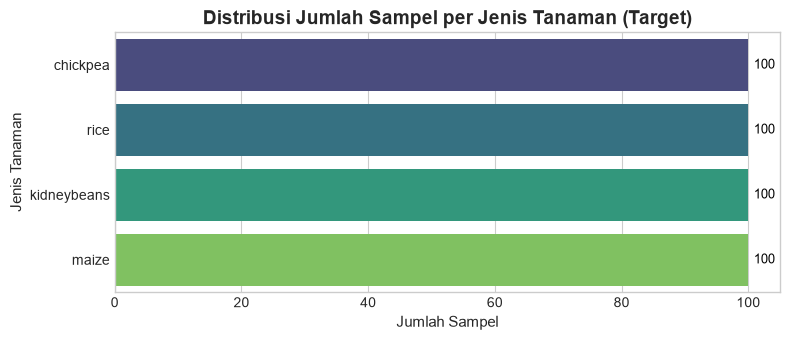

In [7]:
plt.figure(figsize=(8, 3.5))

order = df['label'].value_counts().index
ax = sns.countplot(y='label', data=df, order=order, hue='label', palette='viridis', legend=False)
plt.title('Distribusi Jumlah Sampel per Jenis Tanaman (Target)', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Sampel', fontsize=11)
plt.ylabel('Jenis Tanaman', fontsize=11)

for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}', (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=9, color='black', xytext=(4, 0),
                textcoords='offset points')

plt.tight_layout()
plt.show()

### Buat Visualisasi Data berdasarkan Kandungan Unsur Hara Tanah (N, P, K)

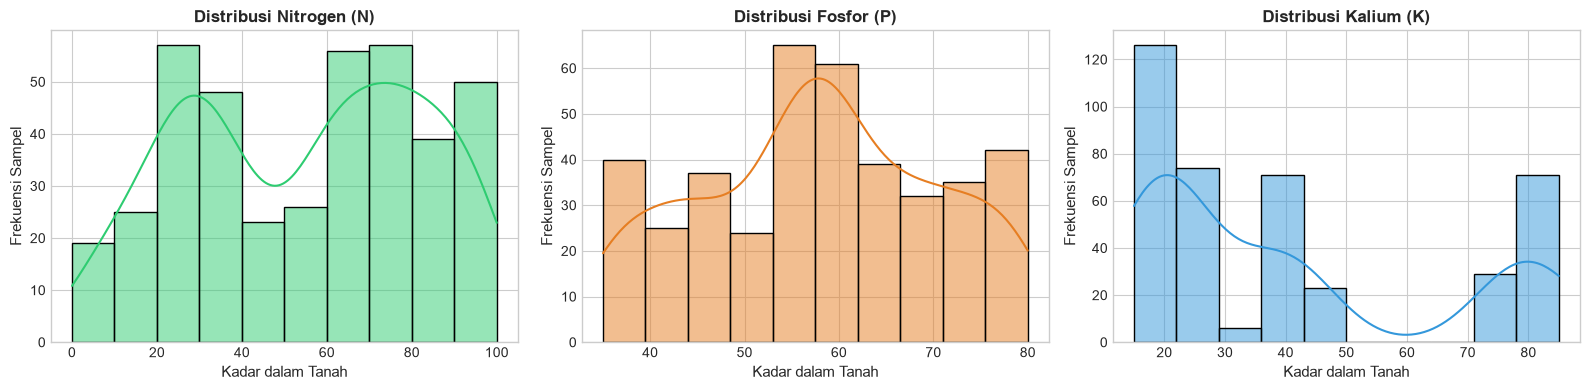

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
warna = ['#2ecc71', '#e67e22', '#3498db']
unsur = [('N', 'Nitrogen (N)'), ('P', 'Fosfor (P)'), ('K', 'Kalium (K)')]

for ax, (kolom, judul), c in zip(axes, unsur, warna):
    sns.histplot(data=df, x=kolom, kde=True, color=c, ax=ax)
    ax.set_title(f'Distribusi {judul}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Kadar dalam Tanah', fontsize=11)
    ax.set_ylabel('Frekuensi Sampel', fontsize=11)

plt.tight_layout()
plt.show()

### Buat Visualisasi Data Berdasarkan Kondisi Iklim (Suhu, Kelembapan, dan Curah Hujan)

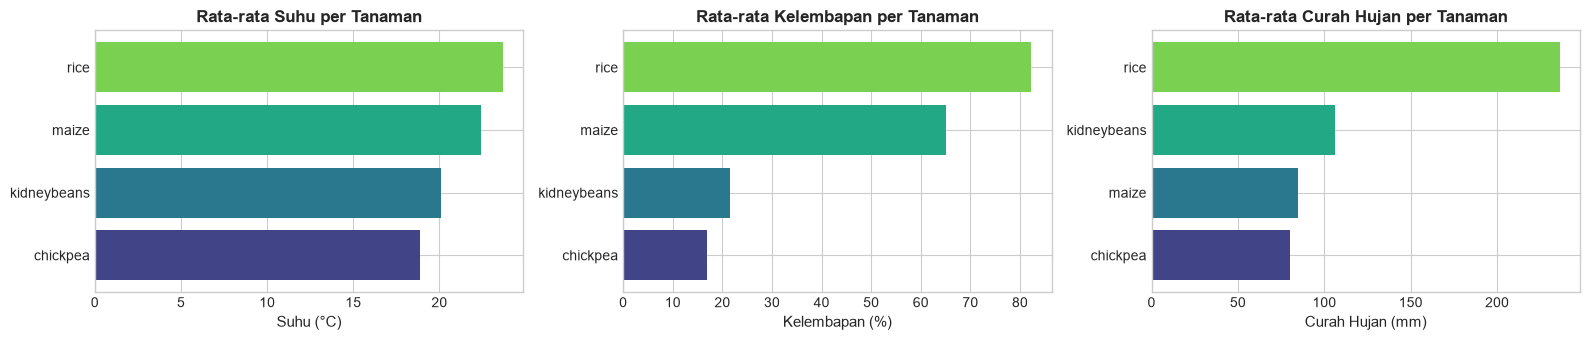

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))

iklim = [('temperature', 'Rata-rata Suhu per Tanaman', 'Suhu (°C)'),
         ('humidity', 'Rata-rata Kelembapan per Tanaman', 'Kelembapan (%)'),
         ('rainfall', 'Rata-rata Curah Hujan per Tanaman', 'Curah Hujan (mm)')]

for ax, (kolom, judul, label_x) in zip(axes, iklim):
    rata = df.groupby('label')[kolom].mean().sort_values()
    ax.barh(rata.index, rata.values, color=sns.color_palette('viridis', len(rata)))
    ax.set_title(judul, fontsize=12, fontweight='bold')
    ax.set_xlabel(label_x, fontsize=11)

plt.tight_layout()
plt.show()

### Buat Visualisasi Korelasi Antar Fitur

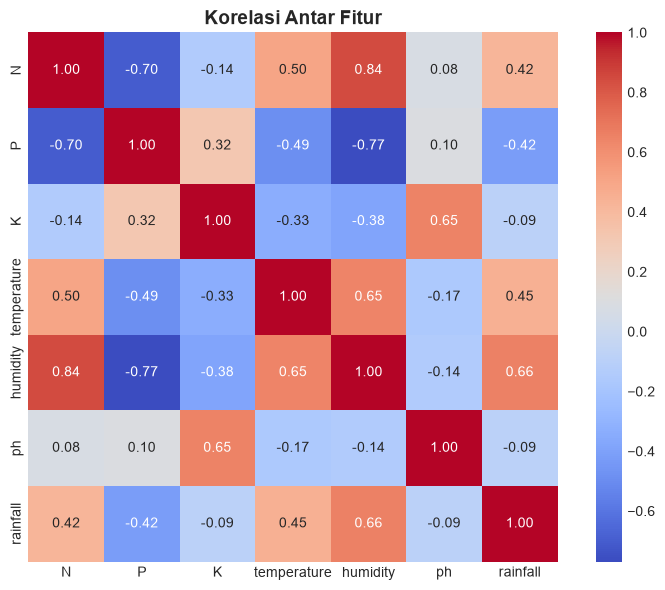

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.drop(columns=['label']).corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Korelasi Antar Fitur', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Hubungan Antara Fitur dan Label (Feature-Label Relationship)

Setelah melihat korelasi antar fitur, langkah berikutnya adalah melihat seberapa kuat setiap fitur berhubungan dengan **label (jenis tanaman)**. Analisis ini dilakukan dengan tiga cara:

1. **Boxplot per kelas**: melihat apakah sebaran nilai suatu fitur berbeda antar tanaman.
2. **ANOVA F-test**: menguji apakah rata-rata fitur berbeda nyata antar kelas (semakin besar nilai F, semakin kuat perbedaannya).
3. **Mutual Information**: mengukur ketergantungan fitur terhadap label, termasuk hubungan non-linear.

Karena label bersifat kategorikal, korelasi Pearson biasa tidak cocok dipakai, sehingga digunakan ukuran-ukuran di atas.

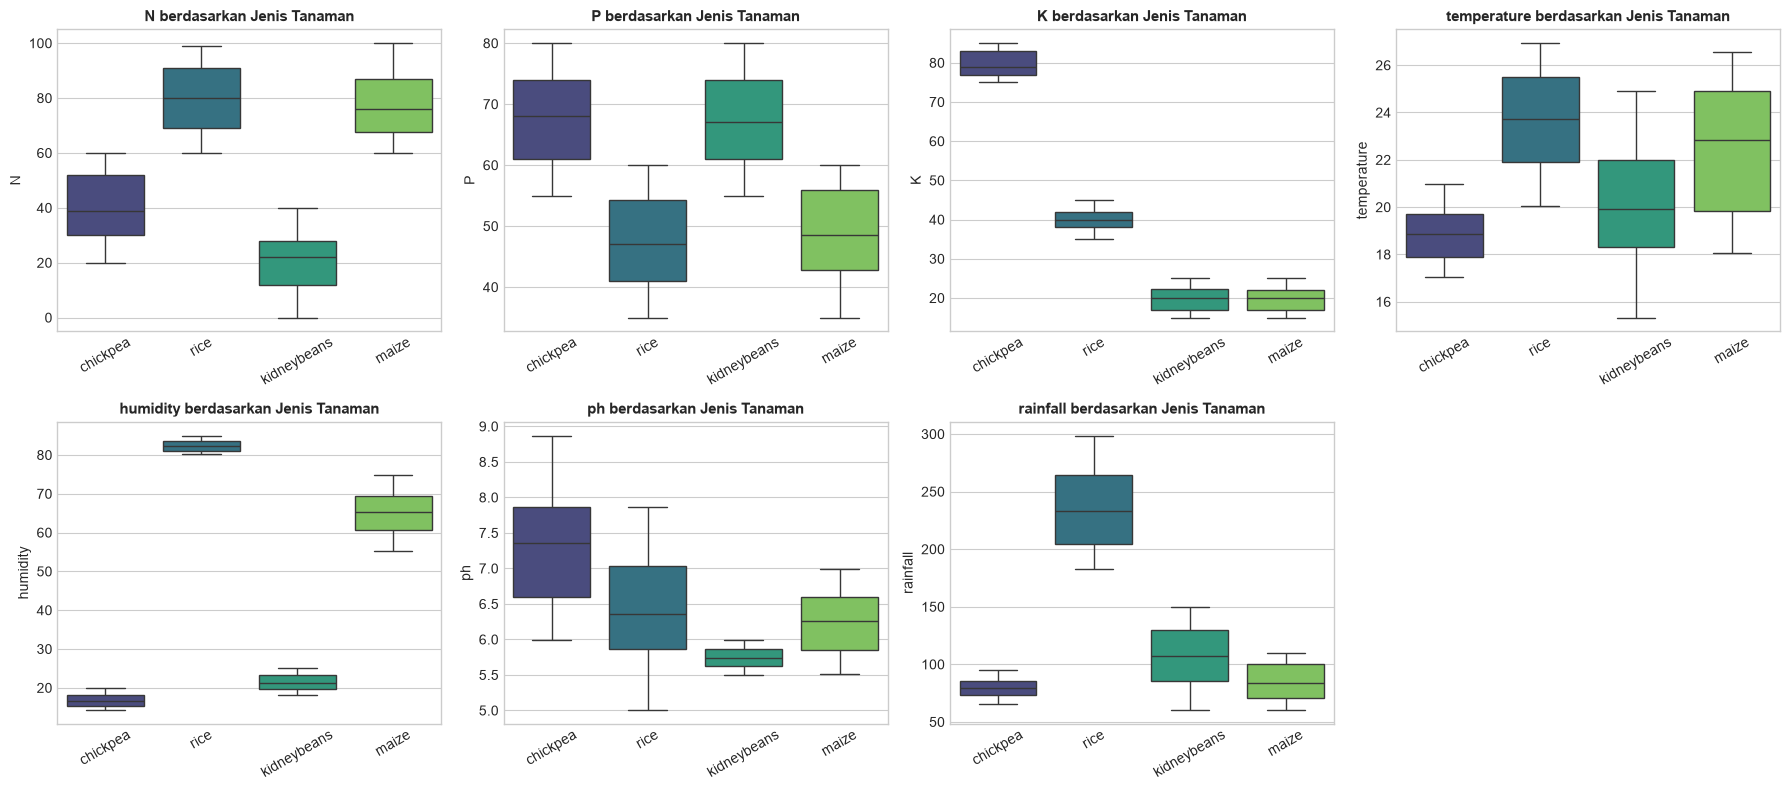

In [11]:
fitur = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for ax, kolom in zip(axes, fitur):
    sns.boxplot(data=df, x='label', y=kolom, hue='label', palette='viridis', legend=False, ax=ax)
    ax.set_title(f'{kolom} berdasarkan Jenis Tanaman', fontsize=11, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)

axes[-1].axis('off')
plt.tight_layout()
plt.show()

--- HUBUNGAN FITUR DENGAN LABEL ---


,F-statistic,p-value,Mutual Information
Fitur,,,
humidity,10589.8553,0.0,1.2779
K,8511.6566,0.0,1.0531
rainfall,1008.1659,0.0,0.8162
N,614.0678,0.0,0.8267
P,214.6599,0.0,0.5077
ph,123.5510,0.0,0.5097
temperature,97.3405,0.0,0.4295


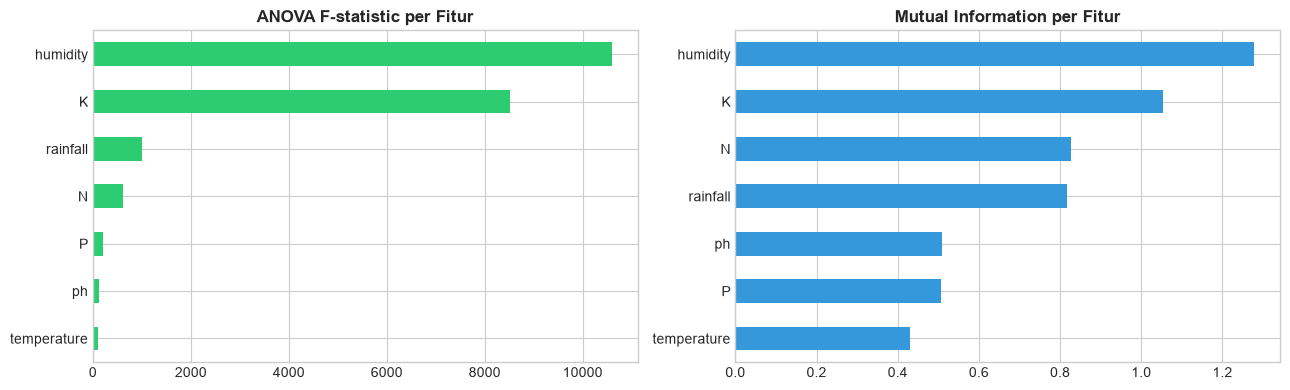

In [12]:
from scipy.stats import f_oneway
from sklearn.feature_selection import mutual_info_classif

y_kode, _ = pd.factorize(df['label'])
kelompok = [df.loc[df['label'] == k] for k in df['label'].unique()]

baris = []
for kolom in fitur:
    F, p = f_oneway(*[g[kolom] for g in kelompok])
    baris.append({'Fitur': kolom, 'F-statistic': F, 'p-value': p})

df_rel = pd.DataFrame(baris).set_index('Fitur')
df_rel['Mutual Information'] = mutual_info_classif(df[fitur], y_kode, random_state=42)
df_rel = df_rel.sort_values('F-statistic', ascending=False)

print("--- HUBUNGAN FITUR DENGAN LABEL ---")
display(df_rel.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_rel['F-statistic'].sort_values().plot.barh(ax=axes[0], color='#2ecc71')
axes[0].set_title('ANOVA F-statistic per Fitur', fontsize=12, fontweight='bold')
df_rel['Mutual Information'].sort_values().plot.barh(ax=axes[1], color='#3498db')
axes[1].set_title('Mutual Information per Fitur', fontsize=12, fontweight='bold')
for ax in axes:
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

**Interpretasi:** Seluruh fitur berhubungan nyata dengan jenis tanaman (p-value < 0,001 pada uji ANOVA), tetapi kekuatannya berbeda. **Kelembapan (humidity)** adalah fitur paling kuat (F ≈ 10.590; MI ≈ 1,28), disusul **Kalium (K)** (F ≈ 8.512; MI ≈ 1,05). Hal ini sejalan dengan boxplot: chickpea dan kidneybeans berkelembapan sangat rendah, rice dan maize jauh lebih lembap, sedangkan K tertinggi dimiliki chickpea. **Curah hujan** dan **Nitrogen (N)** berada di tingkat menengah (rice dibedakan oleh curah hujannya yang tinggi, rice dan maize oleh N yang tinggi). **Fosfor (P)**, **pH**, dan **suhu** paling lemah, tetapi tetap berkontribusi.

Perlu dicatat bahwa urutan N dan curah hujan berbeda antara F-test dan Mutual Information, karena F-test hanya menangkap perbedaan rata-rata sedangkan Mutual Information juga menangkap pola non-linear. Hasil ini juga menjelaskan mengapa keempat tanaman sangat mudah dipisahkan oleh model.

### Encoding Target agar menjadi numerikal

In [13]:
label_encoder = LabelEncoder()
df_encoded = df.copy()
df_encoded['label'] = label_encoder.fit_transform(df['label'])

print("Bentuk dataset sebelum encoding:", df.shape)
print("Bentuk dataset setelah encoding:", df_encoded.shape)
print("\n--- Pemetaan Label ---")
for kode, nama in enumerate(label_encoder.classes_):
    print(f"{kode:>2} = {nama}")

df_encoded.head()

Bentuk dataset sebelum encoding: (400, 8)
Bentuk dataset setelah encoding: (400, 8)

--- Pemetaan Label ---
 0 = chickpea
 1 = kidneybeans
 2 = maize
 3 = rice


,N,P,K,temperature,humidity,ph,rainfall,label
0,28,74,81,18.012723,18.309681,8.753795,81.985688,0
1,54,62,80,17.489117,16.390554,7.489545,79.457583,0
2,98,53,38,20.267076,81.638952,5.014507,270.441727,3
3,58,66,79,20.993736,19.334704,8.718193,93.552801,0
4,78,40,38,26.464283,83.856427,7.549874,248.225649,3


### Memisahkan Data Fitur dengan Target

In [14]:
X = df_encoded.drop(columns=['label'])

y = df_encoded['label']

print("Ukuran Fitur (X):", X.shape)
print("Ukuran Target (y):", y.shape)

Ukuran Fitur (X): (400, 7)
Ukuran Target (y): (400,)


### Split Data untuk Training dan Testing

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Jumlah Data Latih (X_train): {X_train.shape[0]} baris")
print(f"Jumlah Data Uji (X_test)  : {X_test.shape[0]} baris")

Jumlah Data Latih (X_train): 320 baris
Jumlah Data Uji (X_test)  : 80 baris


### Lakukan Standarisasi

In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling berhasil dilakukan!")

Feature scaling berhasil dilakukan!


### Visualisasi Sebelum dan Sesudah Standarisasi

Untuk memastikan standarisasi berjalan dengan benar, distribusi salah satu fitur dibandingkan sebelum dan sesudah `StandardScaler`. Fitur yang ditampilkan adalah **humidity** (kolom dapat diganti lewat variabel `kolom_visual`). Standarisasi hanya mengubah skala data (rata-rata menjadi 0 dan standar deviasi menjadi 1), **tanpa mengubah bentuk distribusinya**.

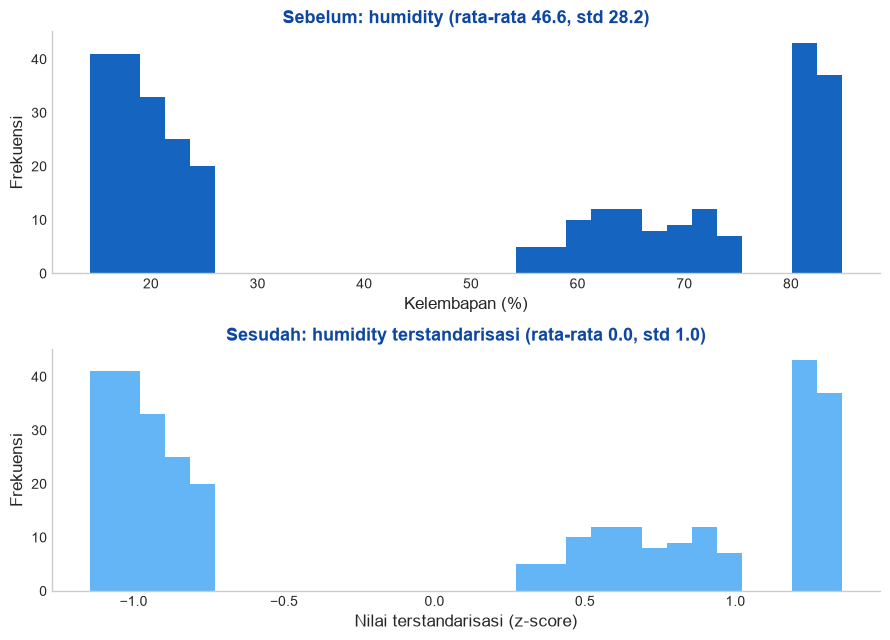

In [17]:
kolom_visual = 'humidity'
label_x = 'Kelembapan (%)'

idx_kolom = list(X.columns).index(kolom_visual)
data_sebelum = X_train[kolom_visual].values
data_sesudah = X_train_scaled[:, idx_kolom]

fig, axes = plt.subplots(2, 1, figsize=(9, 6.5))

# Sebelum standarisasi
axes[0].hist(data_sebelum, bins=30, color='#1565C0')
axes[0].set_title(f'Sebelum: {kolom_visual} (rata-rata {data_sebelum.mean():.1f}, std {data_sebelum.std():.1f})',
                  fontsize=13, fontweight='bold', color='#0D47A1')
axes[0].set_xlabel(label_x, fontsize=12)
axes[0].set_ylabel('Frekuensi', fontsize=12)

# Sesudah standarisasi
axes[1].hist(data_sesudah, bins=30, color='#64B5F6')
axes[1].set_title(f'Sesudah: {kolom_visual} terstandarisasi (rata-rata {data_sesudah.mean():.1f}, std {data_sesudah.std():.1f})',
                  fontsize=13, fontweight='bold', color='#0D47A1')
axes[1].set_xlabel('Nilai terstandarisasi (z-score)', fontsize=12)
axes[1].set_ylabel('Frekuensi', fontsize=12)

for ax in axes:
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Visualisasi Standarisasi pada Dua Fitur (Fungsi Standarisasi)

Visualisasi sebelumnya hanya menunjukkan satu fitur, sehingga fungsi utama standarisasi belum terlihat jelas. Di sini dua fitur dengan skala yang sangat berbeda dibandingkan dalam satu grafik: **curah hujan (`rainfall`)** yang nilainya mencapai ratusan milimeter dan **pH tanah (`ph`)** yang hanya berkisar beberapa satuan.

* **Sebelum standarisasi**, kedua sumbu memakai rentang angka yang sama. Karena rentang `rainfall` jauh lebih besar, sebaran `ph` terlihat pipih dan perbedaannya nyaris tidak terbaca. Inilah yang membuat fitur berskala besar mendominasi pada algoritma yang sensitif terhadap skala.
* **Sesudah standarisasi**, kedua fitur berada pada skala yang sama (rata-rata 0, standar deviasi 1), sehingga kontribusinya seimbang.

Pola sebaran titik (dan pemisahan antar tanaman) tidak berubah, hanya skalanya yang disamakan.

--- RINGKASAN STATISTIK SEBELUM DAN SESUDAH STANDARISASI ---


Min    Maks  Rata-rata    Std
Sebelum rainfall  60.28  298.56     127.05  68.27
        ph         5.01    8.86       6.45   0.83
Sesudah rainfall  -0.98    2.51      -0.00   1.00
        ph        -1.74    2.91       0.00   1.00

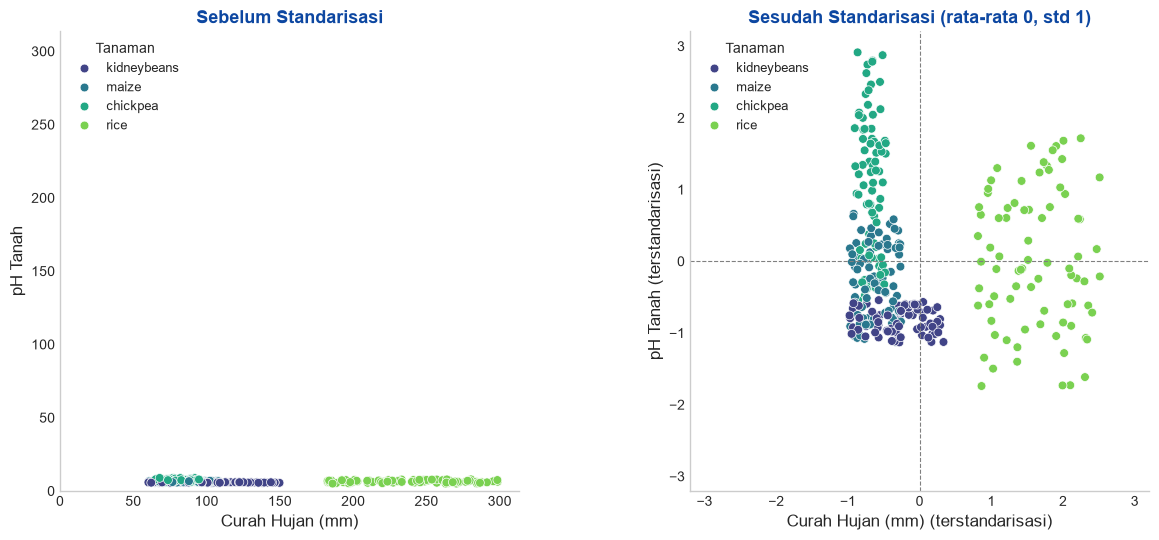

In [18]:
fitur_a, fitur_b = 'rainfall', 'ph'
label_a, label_b = 'Curah Hujan (mm)', 'pH Tanah'

ia = list(X.columns).index(fitur_a)
ib = list(X.columns).index(fitur_b)
nama_kelas = label_encoder.inverse_transform(y_train)

# Data sebelum dan sesudah standarisasi (data latih)
sebelum_a, sebelum_b = X_train[fitur_a].values, X_train[fitur_b].values
sesudah_a, sesudah_b = X_train_scaled[:, ia], X_train_scaled[:, ib]

# Ringkasan statistik
ringkasan = pd.DataFrame({
    'Min': [sebelum_a.min(), sebelum_b.min(), sesudah_a.min(), sesudah_b.min()],
    'Maks': [sebelum_a.max(), sebelum_b.max(), sesudah_a.max(), sesudah_b.max()],
    'Rata-rata': [sebelum_a.mean(), sebelum_b.mean(), sesudah_a.mean(), sesudah_b.mean()],
    'Std': [sebelum_a.std(), sebelum_b.std(), sesudah_a.std(), sesudah_b.std()]
}, index=pd.MultiIndex.from_product([['Sebelum', 'Sesudah'], [fitur_a, fitur_b]]))
print("--- RINGKASAN STATISTIK SEBELUM DAN SESUDAH STANDARISASI ---")
display(ringkasan.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Sebelum: kedua sumbu memakai rentang yang sama agar perbedaan skala terlihat
batas = max(sebelum_a.max(), sebelum_b.max()) * 1.05
sns.scatterplot(x=sebelum_a, y=sebelum_b, hue=nama_kelas, palette='viridis', s=40, ax=axes[0])
axes[0].set_xlim(0, batas)
axes[0].set_ylim(0, batas)
axes[0].set_title('Sebelum Standarisasi', fontsize=13, fontweight='bold', color='#0D47A1')
axes[0].set_xlabel(label_a, fontsize=12)
axes[0].set_ylabel(label_b, fontsize=12)

# Sesudah: kedua fitur berada pada skala yang sama
batas_z = max(np.abs(sesudah_a).max(), np.abs(sesudah_b).max()) * 1.1
sns.scatterplot(x=sesudah_a, y=sesudah_b, hue=nama_kelas, palette='viridis', s=40, ax=axes[1])
axes[1].set_xlim(-batas_z, batas_z)
axes[1].set_ylim(-batas_z, batas_z)
axes[1].axhline(0, color='gray', linewidth=0.8, linestyle='--')
axes[1].axvline(0, color='gray', linewidth=0.8, linestyle='--')
axes[1].set_title('Sesudah Standarisasi (rata-rata 0, std 1)', fontsize=13, fontweight='bold', color='#0D47A1')
axes[1].set_xlabel(f'{label_a} (terstandarisasi)', fontsize=12)
axes[1].set_ylabel(f'{label_b} (terstandarisasi)', fontsize=12)

for ax in axes:
    ax.set_box_aspect(1)
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(title='Tanaman', fontsize=9, title_fontsize=10, loc='upper left', frameon=False)

plt.tight_layout()
plt.show()

### Seleksi Fitur (Feature Selection)

Tidak semua fitur sama pentingnya. Seleksi fitur bertujuan menemukan fitur yang benar-benar berkontribusi, sehingga model lebih sederhana dan petani cukup mengukur parameter yang paling berpengaruh. Seleksi dilakukan **hanya pada data latih** (setelah split dan standarisasi) agar data uji tidak ikut memengaruhi pemilihan fitur.

Tiga metode dipakai, lalu peringkatnya digabung:

1. **ANOVA F-score** (*filter*): ukuran statistik hubungan fitur dengan label.
2. **Feature importance Random Forest** (*embedded*): seberapa besar fitur dipakai model untuk memisahkan kelas.
3. **RFE / Recursive Feature Elimination** (*wrapper*): membuang fitur paling lemah secara bertahap.

Jumlah fitur terbaik (k) kemudian ditentukan dengan cross validation pada data latih.

--- RANKING FITUR (data latih) ---


,F-score (ANOVA),Importance (RF),Ranking RFE,Rank F-score,Rank Importance,Rata-rata Ranking
humidity,8419.267,0.268,1,1.0,1.0,1.000
K,6681.838,0.245,2,2.0,2.0,2.000
rainfall,807.055,0.177,3,3.0,3.0,3.000
N,502.625,0.163,4,4.0,4.0,4.000
ph,96.075,0.070,5,6.0,5.0,5.333
P,179.112,0.063,6,5.0,6.0,5.667
temperature,71.217,0.013,7,7.0,7.0,7.000


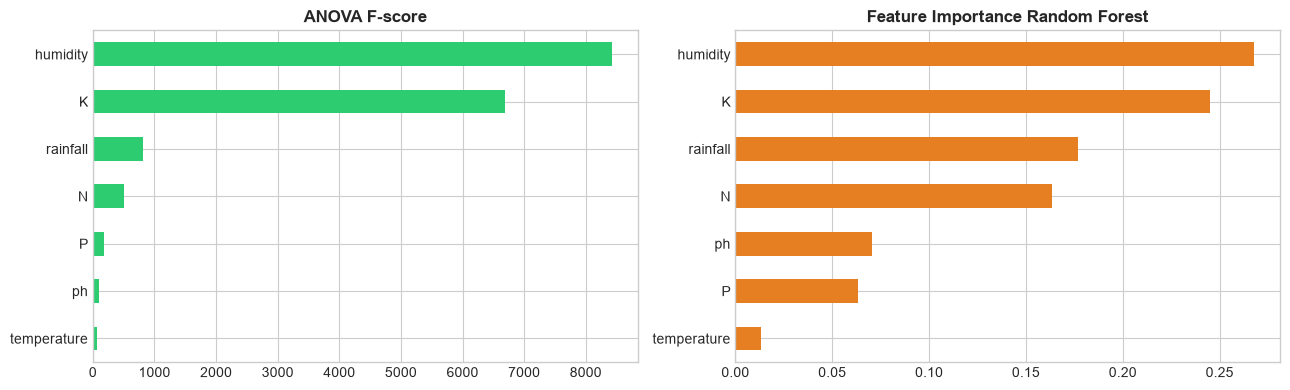

In [19]:
from sklearn.feature_selection import f_classif, RFE

nama_fitur = X.columns.tolist()

# 1) ANOVA F-score
skor_f, _ = f_classif(X_train_scaled, y_train)

# 2) Feature importance Random Forest
rf_seleksi = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_scaled, y_train)

# 3) RFE (ranking 1 = paling penting)
rfe = RFE(RandomForestClassifier(n_estimators=100, random_state=42), n_features_to_select=1).fit(X_train_scaled, y_train)

df_fs = pd.DataFrame({
    'F-score (ANOVA)': skor_f,
    'Importance (RF)': rf_seleksi.feature_importances_,
    'Ranking RFE': rfe.ranking_
}, index=nama_fitur)

df_fs['Rank F-score'] = df_fs['F-score (ANOVA)'].rank(ascending=False)
df_fs['Rank Importance'] = df_fs['Importance (RF)'].rank(ascending=False)
df_fs['Rata-rata Ranking'] = df_fs[['Rank F-score', 'Rank Importance', 'Ranking RFE']].mean(axis=1)
df_fs = df_fs.sort_values('Rata-rata Ranking')

ranking_fitur = df_fs.index.tolist()

print("--- RANKING FITUR (data latih) ---")
display(df_fs.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_fs['F-score (ANOVA)'].sort_values().plot.barh(ax=axes[0], color='#2ecc71')
axes[0].set_title('ANOVA F-score', fontsize=12, fontweight='bold')
df_fs['Importance (RF)'].sort_values().plot.barh(ax=axes[1], color='#e67e22')
axes[1].set_title('Feature Importance Random Forest', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

--- AKURASI CV (data latih) VS JUMLAH FITUR ---


,Random Forest,Naive Bayes
Jumlah Fitur (k),,
1,0.9062,0.9219
2,1.0000,1.0000
3,1.0000,1.0000
4,1.0000,1.0000
5,1.0000,1.0000
6,1.0000,1.0000
7,1.0000,1.0000



Jumlah fitur terbaik (k) : 2
Fitur terpilih           : ['humidity', 'K']


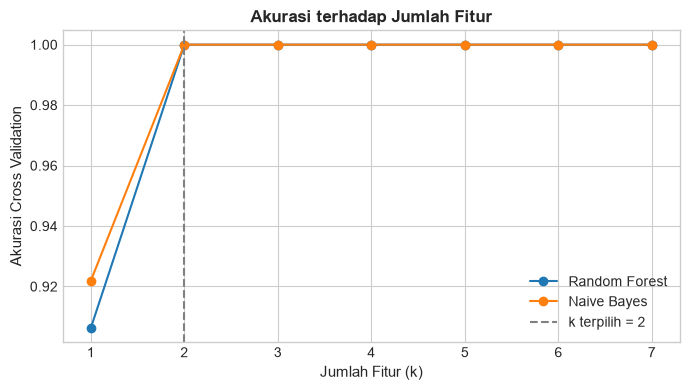

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

skf_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_fs = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Naive Bayes': GaussianNB()
}

hasil_k = {nama: [] for nama in model_fs}
for k in range(1, len(ranking_fitur) + 1):
    kolom_k = ranking_fitur[:k]
    for nama, mdl in model_fs.items():
        skor = cross_val_score(make_pipeline(StandardScaler(), mdl), X_train[kolom_k], y_train, cv=skf_fs)
        hasil_k[nama].append(skor.mean())

df_k = pd.DataFrame(hasil_k, index=range(1, len(ranking_fitur) + 1))
df_k.index.name = 'Jumlah Fitur (k)'

# k terkecil yang sudah mencapai akurasi CV tertinggi pada kedua model
akurasi_maks = df_k.min(axis=1).max()
k_terbaik = int(df_k.index[df_k.min(axis=1) >= akurasi_maks - 1e-12][0])
selected_features = ranking_fitur[:k_terbaik]

print("--- AKURASI CV (data latih) VS JUMLAH FITUR ---")
display(df_k.round(4))
print(f"\nJumlah fitur terbaik (k) : {k_terbaik}")
print(f"Fitur terpilih           : {selected_features}")

plt.figure(figsize=(7, 4))
for nama in df_k.columns:
    plt.plot(df_k.index, df_k[nama], marker='o', label=nama)
plt.axvline(k_terbaik, color='gray', linestyle='--', label=f'k terpilih = {k_terbaik}')
plt.xlabel('Jumlah Fitur (k)', fontsize=11)
plt.ylabel('Akurasi Cross Validation', fontsize=11)
plt.title('Akurasi terhadap Jumlah Fitur', fontsize=12, fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [21]:
hasil_banding = []
for nama, mdl in model_fs.items():
    for label_set, kolom in [(f'Semua fitur ({len(nama_fitur)})', nama_fitur),
                             (f'Fitur terpilih ({len(selected_features)})', selected_features)]:
        pipa = make_pipeline(StandardScaler(), mdl).fit(X_train[kolom], y_train)
        pred = pipa.predict(X_test[kolom])
        hasil_banding.append({
            'Model': nama, 'Set Fitur': label_set,
            'Accuracy': accuracy_score(y_test, pred),
            'F1-Score': f1_score(y_test, pred, average='weighted')
        })

print("--- PERBANDINGAN DATA UJI: SEMUA FITUR VS FITUR TERPILIH ---")
pd.DataFrame(hasil_banding)

--- PERBANDINGAN DATA UJI: SEMUA FITUR VS FITUR TERPILIH ---


,Model,Set Fitur,Accuracy,F1-Score
0,Random Forest,Semua fitur (7),1.0,1.0
1,Random Forest,Fitur terpilih (2),1.0,1.0
2,Naive Bayes,Semua fitur (7),1.0,1.0
3,Naive Bayes,Fitur terpilih (2),1.0,1.0


**Interpretasi:** Ketiga metode memberi urutan yang hampir sama: **humidity** dan **K** selalu di dua teratas, diikuti rainfall dan N, sedangkan suhu paling lemah. Dengan hanya 1 fitur (humidity), akurasi CV sekitar 91-92%, tetapi dengan **2 fitur (humidity dan K)** akurasi CV sudah mencapai 1.00 pada kedua model, sama dengan penggunaan 7 fitur. Pada data uji, hasilnya juga identik (1.00).

Artinya, untuk 4 kelas ini, dua parameter sudah cukup untuk membedakan tanaman. Untuk model akhir dan inferensi di bagian berikutnya, notebook tetap memakai **seluruh 7 fitur** karena tidak merugikan akurasi, lebih tahan terhadap data yang lebih berisik, dan semua parameter tersebut memang tersedia bagi pengguna. Fitur terpilih (`selected_features`) dapat dipakai bila ingin model yang lebih ringkas atau pengukuran lahan yang lebih sederhana.

### Latih Model

In [22]:
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Naive Bayes': GaussianNB()
}

predictions = {}

print("--- Memulai Proses Training Model ---")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    print(f"Model [{name}] selesai dilatih!")

--- Memulai Proses Training Model ---
Model [Random Forest] selesai dilatih!
Model [Naive Bayes] selesai dilatih!


### Print hasil Evaluasi

In [23]:
results_list = []

for name, y_pred in predictions.items():
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    results_list.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1
    })

df_results = pd.DataFrame(results_list)
df_results = df_results.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

print("--- HASIL PERBANDINGAN 2 MODEL MACHINE LEARNING ---")
df_results

--- HASIL PERBANDINGAN 2 MODEL MACHINE LEARNING ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,1.0,1.0,1.0,1.0
1,Naive Bayes,1.0,1.0,1.0,1.0


### Buat Confusion Matrix dari model dengan akurasi tertinggi

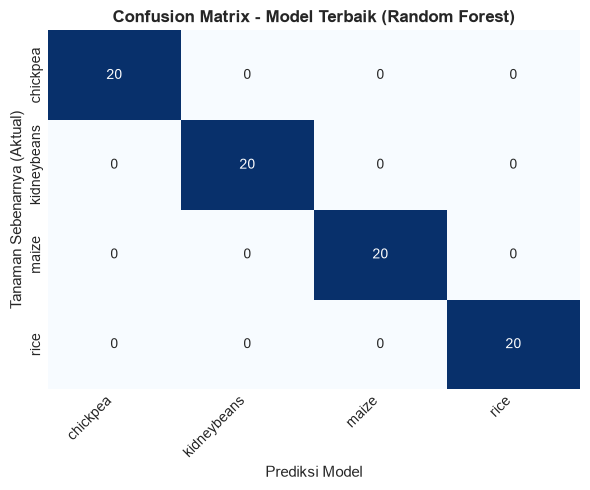


Model Terbaik berdasarkan Akurasi: Random Forest

--- Classification Report ---
              precision    recall  f1-score   support

    chickpea       1.00      1.00      1.00        20
 kidneybeans       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
        rice       1.00      1.00      1.00        20

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



In [24]:
best_model_name = df_results.iloc[0]['Model']
best_pred = predictions[best_model_name]

cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)

plt.title(f'Confusion Matrix - Model Terbaik ({best_model_name})', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Tanaman Sebenarnya (Aktual)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(f"\nModel Terbaik berdasarkan Akurasi: {best_model_name}")
print("\n--- Classification Report ---")
print(classification_report(y_test, best_pred, target_names=label_encoder.classes_, zero_division=0))

### Validasi Silang (Cross Validation)

Evaluasi dengan satu kali pembagian data latih/uji (80 data uji) bisa terlalu optimis atau bergantung pada pembagian yang kebetulan. Untuk memastikan hasil model stabil, dilakukan **Stratified 5-Fold Cross Validation** pada seluruh data (400 sampel). Pada setiap fold, 4/5 data dipakai untuk melatih dan 1/5 untuk menguji, dengan proporsi tiap kelas tetap seimbang.

Proses standarisasi (`StandardScaler`) dimasukkan ke dalam *pipeline* sehingga di-*fit* hanya pada data latih tiap fold. Dengan cara ini tidak ada kebocoran data (*data leakage*) dari data uji ke proses scaling.

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision_weighted',
    'Recall': 'recall_weighted',
    'F1-Score': 'f1_weighted'
}

cv_models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Naive Bayes': GaussianNB()
}

cv_results = {}
cv_summary = []

print("--- Memulai Stratified 5-Fold Cross Validation ---")
for name, model in cv_models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_validate(pipe, X, y, cv=skf, scoring=scoring)
    cv_results[name] = scores

    row = {'Model': name}
    for metrik in scoring:
        hasil = scores[f'test_{metrik}']
        row[f'{metrik} (mean)'] = hasil.mean()
        row[f'{metrik} (std)'] = hasil.std()
    cv_summary.append(row)

    print(f"Model [{name}] selesai: akurasi per fold = {np.round(scores['test_Accuracy'], 4)}")

df_cv = pd.DataFrame(cv_summary).set_index('Model')
print("\n--- HASIL CROSS VALIDATION (5-FOLD) ---")
df_cv.round(4)

--- Memulai Stratified 5-Fold Cross Validation ---
Model [Random Forest] selesai: akurasi per fold = [1. 1. 1. 1. 1.]
Model [Naive Bayes] selesai: akurasi per fold = [1. 1. 1. 1. 1.]

--- HASIL CROSS VALIDATION (5-FOLD) ---


,Accuracy (mean),Accuracy (std),Precision (mean),Precision (std),Recall (mean),Recall (std),F1-Score (mean),F1-Score (std)
Model,,,,,,,,
Random Forest,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
Naive Bayes,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


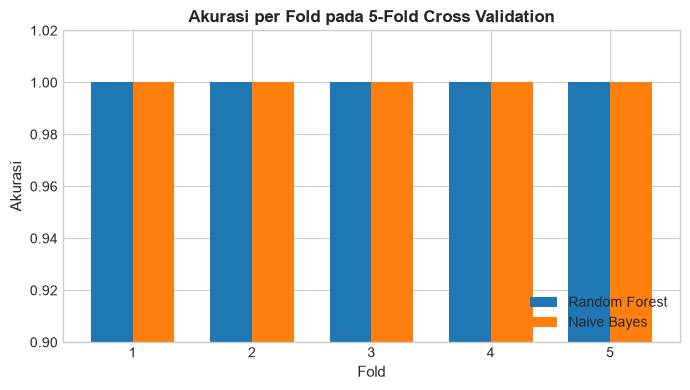

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))

x_fold = np.arange(1, skf.get_n_splits() + 1)
lebar = 0.35
for i, (name, scores) in enumerate(cv_results.items()):
    ax.bar(x_fold + (i - 0.5) * lebar, scores['test_Accuracy'], width=lebar, label=name)

ax.set_xticks(x_fold)
ax.set_xlabel('Fold', fontsize=11)
ax.set_ylabel('Akurasi', fontsize=11)
ax.set_ylim(0.9, 1.02)
ax.set_title('Akurasi per Fold pada 5-Fold Cross Validation', fontsize=12, fontweight='bold')
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

**Interpretasi:** Kedua model mencapai akurasi, presisi, *recall*, dan F1-score 1.00 dengan standar deviasi 0.00 di kelima fold, konsisten dengan hasil pembagian data latih/uji sebelumnya. Artinya hasil tersebut bukan kebetulan dari satu pembagian data. Skor sempurna ini terjadi karena keempat tanaman (rice, maize, chickpea, kidneybeans) memiliki profil tanah dan iklim yang sangat berbeda, sehingga mudah dipisahkan. Pada data lapangan yang lebih beragam dan berisik, performa kemungkinan lebih rendah.

### Inferensi

In [27]:
best_model = models[best_model_name]

# Simulasi 1: ambil satu sampel lahan dari data uji
sample_lahan = X_test.iloc[[0]]
sample_lahan_scaled = scaler.transform(sample_lahan)

prediksi_hasil = best_model.predict(sample_lahan_scaled)[0]
probabilitas = best_model.predict_proba(sample_lahan_scaled)[0]

print("=== HASIL SIMULASI REKOMENDASI TANAMAN (SAMPEL DATA UJI) ===")
print(f"Kondisi Lahan  : {sample_lahan.iloc[0].to_dict()}")
print(f"Tanaman Aktual : {label_encoder.inverse_transform([y_test.iloc[0]])[0]}")
print(f"REKOMENDASI    : {label_encoder.inverse_transform([prediksi_hasil])[0].upper()}")
print(f"Tingkat Keyakinan Model: {probabilitas[prediksi_hasil] * 100:.2f}%")

# Simulasi 2: input lahan baru secara manual
lahan_baru = pd.DataFrame([{
    'N': 90, 'P': 42, 'K': 43,
    'temperature': 21.0, 'humidity': 82.0, 'ph': 6.5, 'rainfall': 203.0
}])[X.columns]

lahan_baru_scaled = scaler.transform(lahan_baru)
probabilitas_baru = best_model.predict_proba(lahan_baru_scaled)[0]
top3 = np.argsort(probabilitas_baru)[::-1][:3]

print("\n=== HASIL SIMULASI REKOMENDASI TANAMAN (LAHAN BARU) ===")
print(f"Kondisi Lahan: {lahan_baru.iloc[0].to_dict()}")
print("3 Rekomendasi Tanaman Teratas:")
for peringkat, idx in enumerate(top3, start=1):
    print(f"  {peringkat}. {label_encoder.classes_[idx]:<12} (keyakinan {probabilitas_baru[idx] * 100:.2f}%)")

=== HASIL SIMULASI REKOMENDASI TANAMAN (SAMPEL DATA UJI) ===
Kondisi Lahan  : {'N': 61.0, 'P': 60.0, 'K': 15.0, 'temperature': 24.87502824, 'humidity': 68.74248334, 'ph': 6.265564338, 'rainfall': 91.26056654}
Tanaman Aktual : maize
REKOMENDASI    : MAIZE
Tingkat Keyakinan Model: 99.00%

=== HASIL SIMULASI REKOMENDASI TANAMAN (LAHAN BARU) ===
Kondisi Lahan: {'N': 90.0, 'P': 42.0, 'K': 43.0, 'temperature': 21.0, 'humidity': 82.0, 'ph': 6.5, 'rainfall': 203.0}
3 Rekomendasi Tanaman Teratas:
  1. rice         (keyakinan 100.00%)
  2. maize        (keyakinan 0.00%)
  3. kidneybeans  (keyakinan 0.00%)
